[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PTB-MR/mrseq/blob/main/examples/t1rho_adiabatic_se_single_line.ipynb)

# Adiabatic T1rho mapping example

The adiabatic preparation block consists of pairs of hyperbolic secant (HS) adiabatic full passage pulses, the second pulse of each pair being phase-inverted, following the 0.55T cardiac implementation of [Si et al.](https://doi.org/10.1002/mrm.30582). The spin-lock time (TSL) is set by the number of HS pulse pairs (TSL = 2 x number of pairs x HS pulse duration).

### Imports

In [1]:
import importlib

if not importlib.util.find_spec('mrseq'):
    %pip install mrseq[examples]

In [2]:
import copy
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import MRzeroCore as mr0
import numpy as np
import pypulseq as pp
import torch
from cmap import Colormap
from einops import rearrange
from mrpro.algorithms.reconstruction import DirectReconstruction
from mrpro.data import KData
from mrpro.data import SpatialDimension
from mrpro.data.traj_calculators import KTrajectoryCartesian
from mrpro.operators import DictionaryMatchOp
from mrpro.operators.models import MonoExponentialDecay

from mrseq.preparations import add_t1rho_adiabatic_prep
from mrseq.sequences.t1rho_se_single_line_prep_switch import main as create_seq
from mrseq.utils import sys_defaults
from mrseq.utils.constants import GYROMAGNETIC_RATIO_PROTON

c:\Users\Lenovo\Documents\code\python_code\mrseq\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Settings
The adiabatic HS pulses have a duration of 15 ms, so the default spin-lock times of 30, 60 and 120 ms correspond to 1, 2 and 4 HS pulse pairs.

In [3]:
image_matrix_size = [128, 128]
hs_pulse_duration = 15e-3  # default HS pulse duration of add_t1rho_adiabatic_prep [s]

tmp = tempfile.TemporaryDirectory()

### Create the digital phantom



In [4]:
phantom = mr0.util.load_phantom(image_matrix_size)
phantom.B1[:] = 1.0
phantom.B0[:] = 0.0

Downloaded simulation data


### Create the adiabatic spin-lock SE sequence

To create the sequence, we use the [t1rho_se_single_line_prep_switch script](../src/mrseq/sequences/t1rho_se_single_line_prep_switch.py)
with `prep_type='adiabatic'`. Setting `prep_type='cw'` would instead create the same sequence with a continuous-wave spin-lock preparation (for comparison)

In [5]:
sequence, fname_seq = create_seq(
    system=sys_defaults,
    prep_type='adiabatic',
    test_report=False,
    timing_check=False,
    show_plots=False,
    fov_xy=float(phantom.size.numpy()[0]),
    n_readout=image_matrix_size[0],
    n_phase_encoding=image_matrix_size[1],
)
spin_lock_times = np.array(sequence.get_definition('TSL'))
print(f'Preparation type: {sequence.get_definition("T1rhoPrepType")}')
print(f'Spin-lock times: {spin_lock_times * 1000} ms')


Minimum TE: 7.465 ms

Saving sequence file 't1rho_se_single_line_prep_switch_adiabatic_200fov_128nx_128ny_3TSLs.seq' into folder 'c:\Users\Lenovo\Documents\code\python_code\mrseq\examples\output'.
Preparation type: adiabatic
Spin-lock times: [ 30.  60. 120.] ms


Visualization of one of the HS pulses of of the preparation block: the amplitude modulation (sech) and the frequency sweep (tanh), which is realized as a phase modulation of the RF pulse.

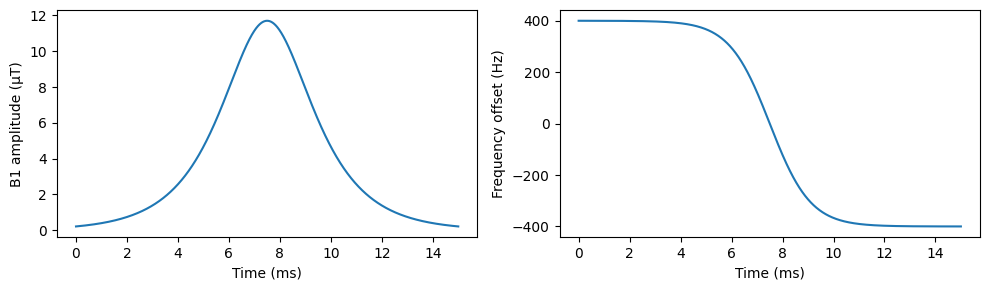

In [6]:
prep_single_pair, _, _ = add_t1rho_adiabatic_prep(system=sys_defaults, n_pairs=1, add_spoiler=False)
hs_pulse = prep_single_pair.get_block(1).rf
hs_amplitude = np.abs(hs_pulse.signal) / GYROMAGNETIC_RATIO_PROTON  # [T]
hs_frequency = np.gradient(np.unwrap(np.angle(hs_pulse.signal)), hs_pulse.t) / (2 * np.pi)  # [Hz]

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(hs_pulse.t * 1000, hs_amplitude * 1e6)
ax[0].set_xlabel('Time (ms)')
ax[0].set_ylabel('B1 amplitude (µT)')
ax[1].plot(hs_pulse.t * 1000, hs_frequency)
ax[1].set_xlabel('Time (ms)')
ax[1].set_ylabel('Frequency offset (Hz)')
fig.tight_layout()

### Simulate the sequence

MRzero approximates every RF pulse as an instantaneous rotation (the integral of the RF waveform). This works for the CW spin-lock preparation, but not for adiabatic pulses, whose effect relies on the time course of amplitude and frequency modulation

We therefore split the simulation into two parts:
1. A time-resolved Bloch simulation of the adiabatic preparation block for every voxel, which yields the longitudinal magnetization
   remaining after each spin-lock time.
2. An MRzero simulation of the spin echo readout, where the proton density of the phantom is scaled by the prepared longitudinal
   magnetization.

Because the preparation ends with a spoiler gradient (no transverse magnetization left) and the long TR ensures full recovery,
this is equivalent to simulating the complete sequence.

In [7]:
def simulate_prep_mz(prep_seq: pp.Sequence, t1: np.ndarray, t2: np.ndarray) -> np.ndarray:
    """Time-resolved on-resonant Bloch simulation of all blocks of a preparation sequence.

    The magnetization starts along +z. RF pulses are applied sample by sample (rotation followed by relaxation),
    all other blocks are treated as free relaxation. Gradients are ignored (spoiling of transverse magnetization is
    irrelevant as only the longitudinal magnetization is returned).
    """
    m = np.zeros((3, *t1.shape))
    m[2] = 1.0

    def relax(m, dt):
        e1, e2 = np.exp(-dt / t1), np.exp(-dt / t2)
        return np.stack([m[0] * e2, m[1] * e2, m[2] * e1 + (1 - e1)])

    def rotate(m, b1, dt):  # rotation around the B1 field in the transverse plane (b1 in Hz, complex)
        angle = 2 * np.pi * np.abs(b1) * dt
        axis = np.array([np.cos(np.angle(b1)), np.sin(np.angle(b1)), 0.0]).reshape(3, *([1] * t1.ndim))
        axis_cross_m = np.cross(axis, m, axis=0)
        axis_dot_m = np.sum(axis * m, axis=0)
        return m * np.cos(angle) - axis_cross_m * np.sin(angle) + axis * axis_dot_m * (1 - np.cos(angle))

    for block_idx in prep_seq.block_events:
        block = prep_seq.get_block(block_idx)
        block_duration = prep_seq.block_durations[block_idx]
        if block.rf is None:
            m = relax(m, block_duration)
            continue
        rf = block.rf
        dwell = rf.t[1] - rf.t[0]
        m = relax(m, rf.delay)
        for sample in rf.signal * np.exp(1j * rf.phase_offset):
            m = relax(rotate(m, sample, dwell), dwell)
        m = relax(m, block_duration - rf.delay - len(rf.signal) * dwell)
    return m[2]

First, we simulate the longitudinal magnetization after the adiabatic preparation for each spin-lock time:

In [8]:
t1 = phantom.T1.numpy()
t2 = phantom.T2.numpy()
tissue = (t1 > 0) & (t2 > 0)

mz_prep = []
for tsl in spin_lock_times:
    prep, _, _ = add_t1rho_adiabatic_prep(system=sys_defaults, n_pairs=round(tsl / (2 * hs_pulse_duration)))
    mz = np.ones_like(t1)
    mz[tissue] = simulate_prep_mz(prep, t1[tissue], t2[tissue])
    mz_prep.append(mz)

Then, we create the same sequence without preparation (spin-lock time of 0) and simulate the readout with MRzero for each spin-lock time, using the prepared magnetization as proton density. The simulated signals are saved as (ISMR)MRD files

In [9]:
sequence_readout, fname_seq_readout = create_seq(
    system=sys_defaults,
    prep_type='adiabatic',
    spin_lock_times=np.array([0.0]),
    test_report=False,
    timing_check=False,
    show_plots=False,
    fov_xy=float(phantom.size.numpy()[0]),
    n_readout=image_matrix_size[0],
    n_phase_encoding=image_matrix_size[1],
)
mr0_sequence = mr0.Sequence.import_file(str(fname_seq_readout.with_suffix('.seq')))

fnames_mrd = []
for tsl_idx, mz in enumerate(mz_prep):
    phantom_prepared = copy.deepcopy(phantom)
    phantom_prepared.PD = phantom.PD * torch.as_tensor(mz)
    signal, ktraj_adc = mr0.util.simulate(mr0_sequence, phantom_prepared, accuracy=1e-5)
    fnames_mrd.append(Path(tmp.name) / f't1rho_adiabatic_tsl{tsl_idx}.mrd')
    mr0.sig_to_mrd(fnames_mrd[-1], signal, sequence_readout)


Minimum TE: 7.465 ms

Saving sequence file 't1rho_se_single_line_prep_switch_adiabatic_200fov_128nx_128ny_1TSLs.seq' into folder 'c:\Users\Lenovo\Documents\code\python_code\mrseq\examples\output'.


### Reconstruct the images at different spin-lock times
We use [MRpro](https://github.com/PTB-MR/MRpro) for the image reconstruction

In [10]:
images = []
for fname_mrd in fnames_mrd:
    kdata = KData.from_file(fname_mrd, trajectory=KTrajectoryCartesian())
    kdata.header.encoding_matrix = SpatialDimension(z=1, y=image_matrix_size[1], x=image_matrix_size[0])
    kdata.header.recon_matrix = SpatialDimension(z=1, y=image_matrix_size[1], x=image_matrix_size[0])
    recon = DirectReconstruction(kdata, csm=None)
    images.append(recon(kdata).data)
idata = torch.cat(images, dim=0)

c:\Users\Lenovo\Documents\code\python_code\mrseq\.venv\lib\site-packages\mrpro\data\KData.py:367: UserWarning: No vendor information found. Assuming Siemens time stamp format.
  warnings.warn('No vendor information found. Assuming Siemens time stamp format.', stacklevel=1)


Lastly, we plot the images at different spin-lock times

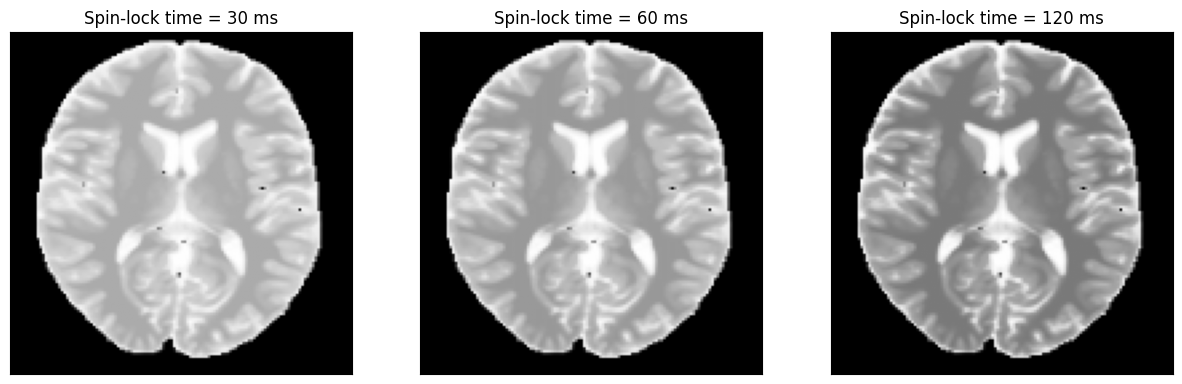

In [11]:
idat = idata.abs().numpy().squeeze()
fig, ax = plt.subplots(1, idat.shape[0], figsize=(5 * idat.shape[0], 5))
for i in range(idat.shape[0]):
    ax[i].imshow(idat[i, :, :], cmap='gray')
    ax[i].set_title(f'Spin-lock time = {int(spin_lock_times[i] * 1000)} ms')
    ax[i].set_xticks([])
    ax[i].set_yticks([])

### Estimate the adiabatic T1rho maps
We use a dictionary matching approach to estimate the adiabatic T1rho maps.

The phantom does not have a specific T1rho model. During an adiabatic pulse, the magnetization is locked along the effective field,
whose angle $\alpha(t)$ to the z-axis changes during the frequency sweep. The relaxation rate is therefore a weighted average of R1 and R2:

$$R_{1\rho,\mathrm{adiab}} = \left\langle \cos^2\alpha(t) \right\rangle R_1 + \left\langle \sin^2\alpha(t) \right\rangle R_2, \qquad \tan\alpha(t) = \frac{\omega_1(t)}{\Delta\omega(t)}$$

with the average taken over the HS pulse. We use this as reference. As in the CW example, the long T2 of CSF prevents a proper
estimation, so we exclude it from the comparison.

Average sin^2(alpha) of the HS pulse: 0.245
Relative error 0.00916691217571497


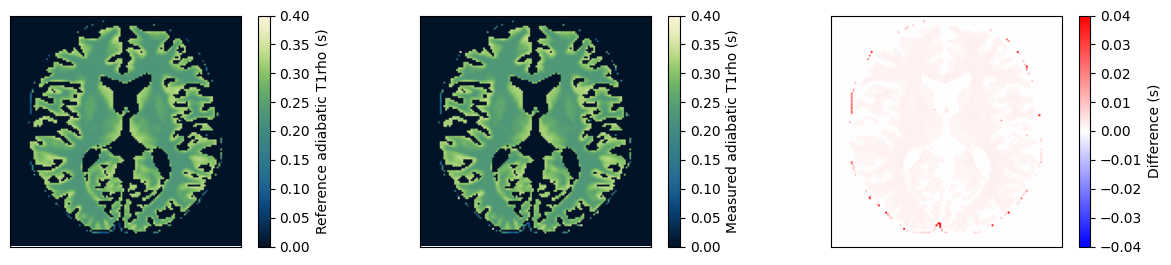

In [ ]:
sin2_alpha = np.mean(np.sin(np.arctan2(np.abs(hs_pulse.signal), hs_frequency)) ** 2)
print(f'Average sin^2(alpha) of the HS pulse: {sin2_alpha:.3f}')

t1rho_ref = np.zeros_like(t1)
t1rho_ref[tissue] = 1 / ((1 - sin2_alpha) / t1[tissue] + sin2_alpha / t2[tissue])

dictionary = DictionaryMatchOp(
    MonoExponentialDecay(decay_time=torch.as_tensor(spin_lock_times)), index_of_scaling_parameter=0
)
dictionary.append(torch.tensor(1.0), torch.linspace(0.01, 0.8, 1000)[None, :])
m0_match, t1rho_match = dictionary(idata[:, 0, 0])


def to_image_orientation(x):
    """Flip and transpose phantom maps to match the orientation of the reconstructed images."""
    return np.roll(rearrange(x.squeeze()[::-1, ::-1], 'x y -> y x'), shift=(1, 1), axis=(0, 1))


t2_input = to_image_orientation(t2)
obj_mask = np.zeros_like(t2_input)
obj_mask[(t2_input > 0) & (t2_input < 0.1)] = 1
t1rho_input = to_image_orientation(t1rho_ref) * obj_mask
t1rho_measured = t1rho_match.numpy().squeeze() * obj_mask

fig, ax = plt.subplots(1, 3, figsize=(15, 3))
for cax in ax:
    cax.set_xticks([])
    cax.set_yticks([])

im = ax[0].imshow(t1rho_input, vmin=0, vmax=0.4, cmap=Colormap('navia').to_mpl())
fig.colorbar(im, ax=ax[0], label='Reference adiabatic T1rho (s)')

im = ax[1].imshow(t1rho_measured, vmin=0, vmax=0.4, cmap=Colormap('navia').to_mpl())
fig.colorbar(im, ax=ax[1], label='Measured adiabatic T1rho (s)')

im = ax[2].imshow(t1rho_measured - t1rho_input, vmin=-0.04, vmax=0.04, cmap='bwr')
fig.colorbar(im, ax=ax[2], label='Difference (s)')

relative_error = np.sum(np.abs(t1rho_input - t1rho_measured)) / np.sum(np.abs(t1rho_input))
print(f'Relative error {relative_error}')
assert relative_error < 0.05